In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as py
import seaborn as sns
import warnings as wn
wn.filterwarnings("ignore")
%pylab inline

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Populating the interactive namespace from numpy and matplotlib


In [2]:
data=pd.read_excel("/MapAnalysis.xlsx")

In [3]:
data

,Farm,Code,Latitude,Longitude,Mass (g) (Range),Cultivated Crop/Crop Collected
0,Farm 1,F1 P1,9.719682,8.907813,133.33 – 151.20,Only maize planted. Matured maize cobs were co...
1,Farm 1,F1 P2,9.720013,8.908152,145.72 – 154.14,Only maize planted. Matured maize cobs were co...
2,Farm 2,F2 P1,9.707172,8.898151,112.29 – 145.94,Undergoing preparation for planting. Tomatoes ...
3,Farm 2,F2 P2,9.707170,8.898145,107.15 – 159.31,Undergoing preparation for planting. Tomatoes ...
4,Farm 3,F3 P1,9.711612,8.911994,124.42 – 151.56,Maize planted still in developing stage. No cr...
5,Farm 3,F3 P2,9.711618,8.911950,138.96 – 150.36,Maize planted still in developing stage. No cr...
6,Farm 4,F4 P1,9.712002,8.912246,150.20 – 150.86,"Vegetables cultivated. Spinach, green pepper a..."
7,Farm 4,F4 P2,9.712024,8.912131,135.47 – 153.23,"Vegetables cultivated. Spinach, green pepper a..."
8,Farm 5,F5 P1,9.707980,8.909903,119.16 – 153.75,Maize planted but at early stage with no cub. ...
9,Farm 5,F5 P2,9.708097,8.909864,117.64 – 151.59,Maize planted but at early stage with no cub. ...


In [4]:
data.isnull().sum()

Farm                              0
Code                              0
Latitude                          0
Longitude                         0
Mass (g) (Range)                  0
Cultivated Crop/Crop Collected    0
dtype: int64

In [5]:
data.describe()

,Latitude,Longitude
count,18.000000,18.000000
mean,9.711949,8.906864
std,0.003528,0.004306
min,9.707170,8.898145
25%,9.710504,8.905144
50%,9.712001,8.907113
75%,9.712540,8.909893
max,9.720013,8.912246


In [6]:

# Display the first five rows
print(data.head())

# Check the number of rows and columns
print("Dataset shape:", data.shape)

# Display all column names
print("Column names:")
print(data.columns.tolist())


     Farm   Code  Latitude  Longitude Mass (g) (Range)  \
0  Farm 1  F1 P1  9.719682   8.907813  133.33 – 151.20   
1  Farm 1  F1 P2  9.720013   8.908152  145.72 – 154.14   
2  Farm 2  F2 P1  9.707172   8.898151  112.29 – 145.94   
3  Farm 2  F2 P2  9.707170   8.898145  107.15 – 159.31   
4  Farm 3  F3 P1  9.711612   8.911994  124.42 – 151.56   

                      Cultivated Crop/Crop Collected  
0  Only maize planted. Matured maize cobs were co...  
1  Only maize planted. Matured maize cobs were co...  
2  Undergoing preparation for planting. Tomatoes ...  
3  Undergoing preparation for planting. Tomatoes ...  
4  Maize planted still in developing stage. No cr...  
Dataset shape: (18, 6)
Column names:
['Farm', 'Code', 'Latitude', 'Longitude', 'Mass (g) (Range)', 'Cultivated Crop/Crop Collected']


In [7]:
# Check data types and non-null values
data.info()

# Count missing values in every column
print("\nMissing values:")
print(data.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:", data.duplicated().sum())

# Check the numerical columns
print("\nNumerical summary:")



<class 'pandas.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 6 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Farm                            18 non-null     str    
 1   Code                            18 non-null     str    
 2   Latitude                        18 non-null     float64
 3   Longitude                       18 non-null     float64
 4   Mass (g) (Range)                18 non-null     str    
 5   Cultivated Crop/Crop Collected  18 non-null     str    
dtypes: float64(2), str(4)
memory usage: 2.7 KB

Missing values:
Farm                              0
Code                              0
Latitude                          0
Longitude                         0
Mass (g) (Range)                  0
Cultivated Crop/Crop Collected    0
dtype: int64

Number of duplicate rows: 0

Numerical summary:


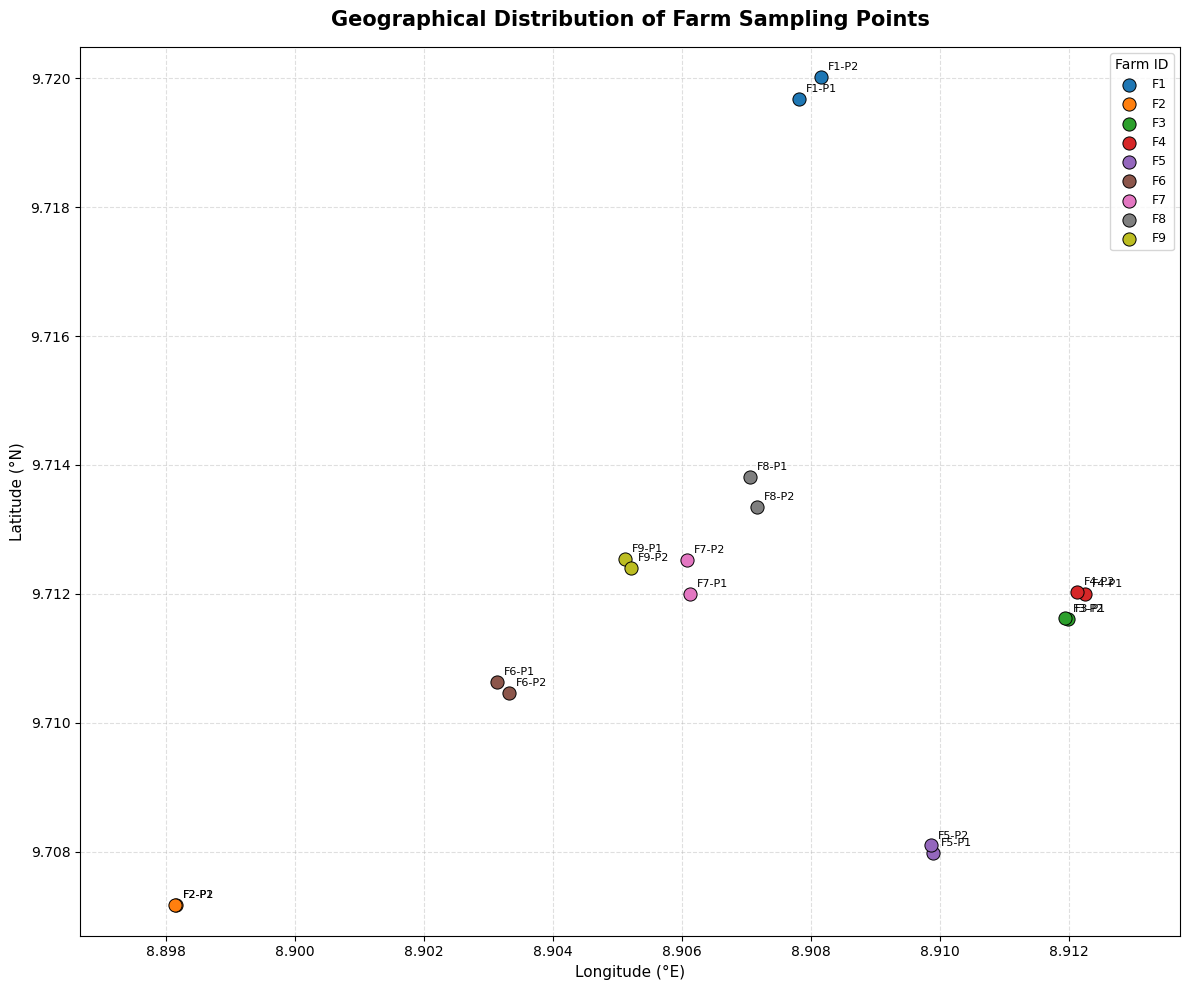

Number of farms: 9
Number of sampling points: 18
Saved: farm_sampling_map.png
Saved: farm_sampling_map.pdf


In [9]:

import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

# ==========================================
# 1. FARM SAMPLING DATA
# ==========================================

data = [
    ["F1", "P1", 9.719682, 8.907813, "Matured maize cobs", "133.33–151.20 g"],
    ["F1", "P2", 9.720013, 8.908152, "Matured maize cobs", "145.72–154.14 g"],
    ["F2", "P1", 9.707172, 8.898151, "Tomatoes", "112.29–145.94 g"],
    ["F2", "P2", 9.707170, 8.898145, "Tomatoes", "107.15–159.31 g"],
    ["F3", "P1", 9.711612, 8.911994, "Developing maize", "124.42–151.56 g"],
    ["F3", "P2", 9.711618, 8.911950, "Developing maize", "138.96–150.36 g"],
    ["F4", "P1", 9.712002, 8.912246, "Vegetables", "150.20–150.86 g"],
    ["F4", "P2", 9.712024, 8.912131, "Vegetables", "135.47–153.23 g"],
    ["F5", "P1", 9.707980, 8.909903, "Early-stage maize", "119.16–153.75 g"],
    ["F5", "P2", 9.708097, 8.909864, "Early-stage maize", "117.64–151.59 g"],
    ["F6", "P1", 9.710628, 8.903125, "Maize and guinea corn", "102.00–159.73 g"],
    ["F6", "P2", 9.710463, 8.903319, "Maize and guinea corn", "117.14–146.37 g"],
    ["F7", "P1", 9.712000, 8.906121, "Tender-stage maize", "117.55–149.88 g"],
    ["F7", "P2", 9.712520, 8.906075, "Tender-stage maize", "127.42–149.29 g"],
    ["F8", "P1", 9.713813, 8.907058, "Bidens pilosa", "95.45–151.53 g"],
    ["F8", "P2", 9.713344, 8.907169, "Bidens pilosa", "109.72–151.31 g"],
    ["F9", "P1", 9.712547, 8.905120, "Early-stage carrots", "121.25–155.50 g"],
    ["F9", "P2", 9.712396, 8.905217, "Early-stage carrots", "102.12–153.64 g"],
]

df = pd.DataFrame(
    data,
    columns=[
        "Farm", "Point", "Latitude", "Longitude",
        "Crop", "Mass_Range"
    ]
)

# ==========================================
# 2. CONVERT COORDINATES TO GEOGRAPHIC POINTS
# ==========================================

gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["Longitude"], df["Latitude"]),
    crs="EPSG:4326"
)

# ==========================================
# 3. PLOT THE SAMPLING LOCATIONS
# ==========================================

fig, ax = plt.subplots(figsize=(12, 10))

# One colour per farm
colors = plt.cm.tab10.colors

for i, farm in enumerate(sorted(gdf["Farm"].unique())):
    subset = gdf[gdf["Farm"] == farm]

    subset.plot(
        ax=ax,
        color=colors[i % len(colors)],
        markersize=90,
        edgecolor="black",
        linewidth=0.7,
        label=farm,
        zorder=3
    )

    # Label each sampling point
    for _, row in subset.iterrows():
        ax.annotate(
            f'{row["Farm"]}-{row["Point"]}',
            xy=(row.geometry.x, row.geometry.y),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

# ==========================================
# 4. FORMAT THE MAP
# ==========================================

ax.set_title(
    "Geographical Distribution of Farm Sampling Points",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Longitude (°E)", fontsize=11)
ax.set_ylabel("Latitude (°N)", fontsize=11)

ax.legend(
    title="Farm ID",
    loc="best",
    fontsize=9
)

ax.grid(True, linestyle="--", alpha=0.4)
ax.set_aspect("equal", adjustable="datalim")

plt.tight_layout()

# ==========================================
# 5. SAVE AND DISPLAY THE MAP
# ==========================================

plt.savefig(
    "farm_sampling_map.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "farm_sampling_map.pdf",
    bbox_inches="tight"
)

plt.show()

print("Number of farms:", gdf["Farm"].nunique())
print("Number of sampling points:", len(gdf))
print("Saved: farm_sampling_map.png")
print("Saved: farm_sampling_map.pdf")


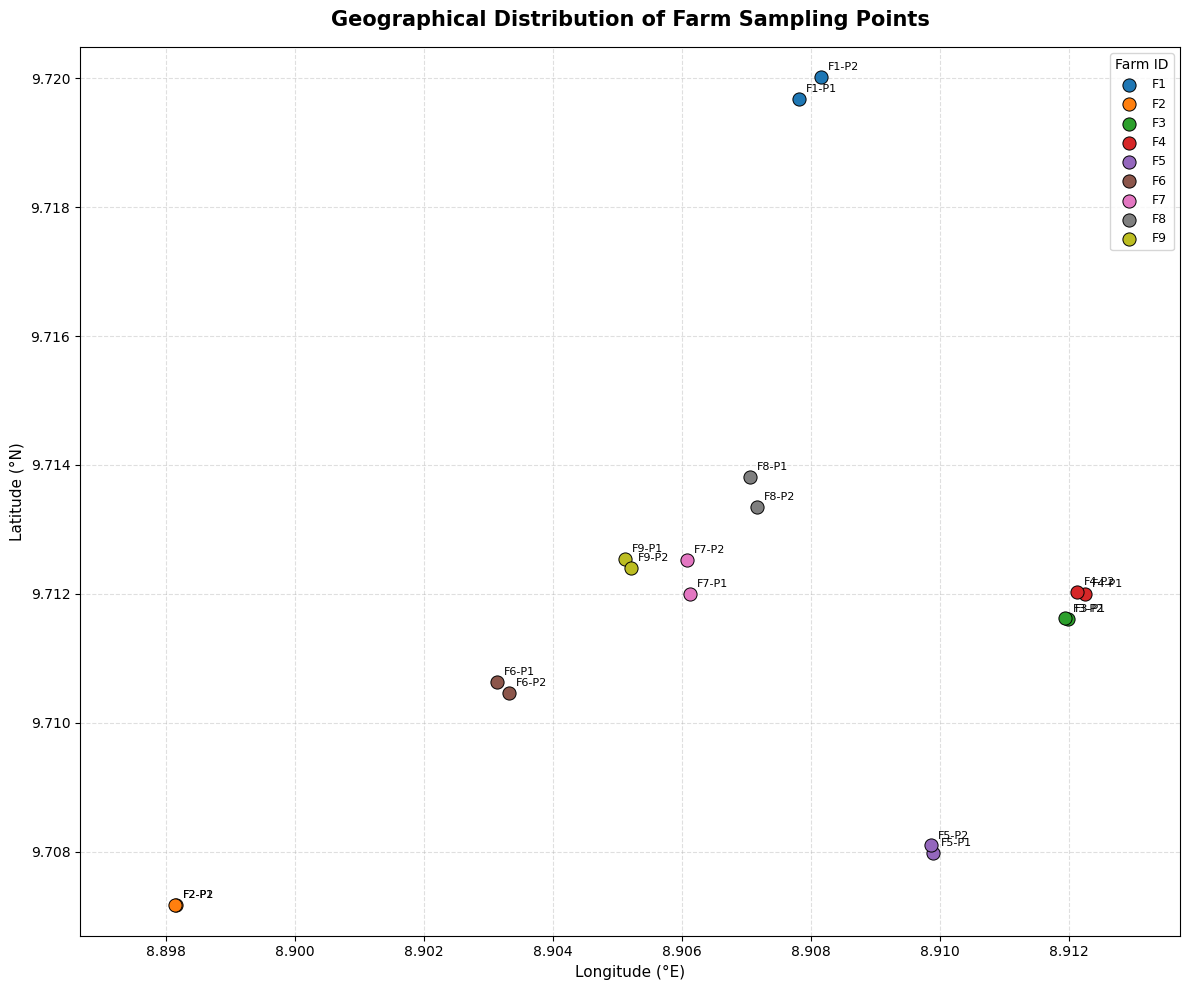

Number of farms: 9
Number of sampling points: 18
Saved: farm_sampling_map.png
Saved: farm_sampling_map.pdf


In [10]:

import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

# ==========================================
# 1. FARM SAMPLING DATA
# ==========================================

data = [
    ["F1", "P1", 9.719682, 8.907813, "Matured maize cobs", "133.33–151.20 g"],
    ["F1", "P2", 9.720013, 8.908152, "Matured maize cobs", "145.72–154.14 g"],
    ["F2", "P1", 9.707172, 8.898151, "Tomatoes", "112.29–145.94 g"],
    ["F2", "P2", 9.707170, 8.898145, "Tomatoes", "107.15–159.31 g"],
    ["F3", "P1", 9.711612, 8.911994, "Developing maize", "124.42–151.56 g"],
    ["F3", "P2", 9.711618, 8.911950, "Developing maize", "138.96–150.36 g"],
    ["F4", "P1", 9.712002, 8.912246, "Vegetables", "150.20–150.86 g"],
    ["F4", "P2", 9.712024, 8.912131, "Vegetables", "135.47–153.23 g"],
    ["F5", "P1", 9.707980, 8.909903, "Early-stage maize", "119.16–153.75 g"],
    ["F5", "P2", 9.708097, 8.909864, "Early-stage maize", "117.64–151.59 g"],
    ["F6", "P1", 9.710628, 8.903125, "Maize and guinea corn", "102.00–159.73 g"],
    ["F6", "P2", 9.710463, 8.903319, "Maize and guinea corn", "117.14–146.37 g"],
    ["F7", "P1", 9.712000, 8.906121, "Tender-stage maize", "117.55–149.88 g"],
    ["F7", "P2", 9.712520, 8.906075, "Tender-stage maize", "127.42–149.29 g"],
    ["F8", "P1", 9.713813, 8.907058, "Bidens pilosa", "95.45–151.53 g"],
    ["F8", "P2", 9.713344, 8.907169, "Bidens pilosa", "109.72–151.31 g"],
    ["F9", "P1", 9.712547, 8.905120, "Early-stage carrots", "121.25–155.50 g"],
    ["F9", "P2", 9.712396, 8.905217, "Early-stage carrots", "102.12–153.64 g"],
]

df = pd.DataFrame(
    data,
    columns=[
        "Farm", "Point", "Latitude", "Longitude",
        "Crop", "Mass_Range"
    ]
)

# ==========================================
# 2. CONVERT COORDINATES TO GEOGRAPHIC POINTS
# ==========================================

gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["Longitude"], df["Latitude"]),
    crs="EPSG:4326"
)

# ==========================================
# 3. PLOT THE SAMPLING LOCATIONS
# ==========================================

fig, ax = plt.subplots(figsize=(12, 10))

# One colour per farm
colors = plt.cm.tab10.colors

for i, farm in enumerate(sorted(gdf["Farm"].unique())):
    subset = gdf[gdf["Farm"] == farm]

    subset.plot(
        ax=ax,
        color=colors[i % len(colors)],
        markersize=90,
        edgecolor="black",
        linewidth=0.7,
        label=farm,
        zorder=3
    )

    # Label each sampling point
    for _, row in subset.iterrows():
        ax.annotate(
            f'{row["Farm"]}-{row["Point"]}',
            xy=(row.geometry.x, row.geometry.y),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

# ==========================================
# 4. FORMAT THE MAP
# ==========================================

ax.set_title(
    "Geographical Distribution of Farm Sampling Points",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Longitude (°E)", fontsize=11)
ax.set_ylabel("Latitude (°N)", fontsize=11)

ax.legend(
    title="Farm ID",
    loc="best",
    fontsize=9
)

ax.grid(True, linestyle="--", alpha=0.4)
ax.set_aspect("equal", adjustable="datalim")

plt.tight_layout()

# ==========================================
# 5. SAVE AND DISPLAY THE MAP
# ==========================================

plt.savefig(
    "farm_sampling_map.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "farm_sampling_map.pdf",
    bbox_inches="tight"
)

plt.show()

print("Number of farms:", gdf["Farm"].nunique())
print("Number of sampling points:", len(gdf))
print("Saved: farm_sampling_map.png")
print("Saved: farm_sampling_map.pdf")


In [ ]:
%pip install contextily geopandas

In [11]:
import numpy as np
import pandas as pd
from io import StringIO
import xyzservices.providers as xyz
from bokeh.io import output_notebook, show
from bokeh.plotting import figure
from bokeh.models import ColumnDataSource, HoverTool, LabelSet
from bokeh.transform import factor_cmap
from bokeh.palettes import Category10

output_notebook()

csv_data = """Farm,Code,Latitude,Longitude,Mass_Range_g
Farm 1,F1 P1,4.859841,4.4539065,133.33 – 151.20
Farm 1,F1 P2,4.8600065,4.454076,145.72 – 154.14
Farm 2,F2 P1,4.853586,4.4490755,112.29 – 145.94
Farm 2,F2 P2,4.853585,4.4490725,107.15 – 159.31
Farm 3,F3 P1,4.855806,4.455997,124.42 – 151.56
Farm 3,F3 P2,4.855809,4.455975,138.96 – 150.36
Farm 4,F4 P1,4.856001,4.456123,150.20 – 150.86
Farm 4,F4 P2,4.856012,4.4560655,135.47 – 153.23
Farm 5,F5 P1,4.85399,4.4549515,119.16 – 153.75
Farm 5,F5 P2,4.8540485,4.454932,117.64 – 151.59
Farm 6,F6 P1,4.855314,4.4515625,102.00 – 159.73
Farm 6,F6 P2,4.8552315,4.4516595,117.14 – 146.37
Farm 7,F7 P1,4.856,4.4530605,117.55 – 149.88
Farm 7,F7 P2,4.85626,4.4530375,127.42 – 149.29
Farm 8,F8 P1,4.8569065,4.453529,95.45 – 151.53
Farm 8,F8 P2,4.856672,4.4535845,109.72 – 151.31
Farm 9,F9 P1,4.8562735,4.45256,121.25 – 155.50
Farm 9,F9 P2,4.856198,4.4526085,102.12 – 153.64
"""

data = pd.read_csv(StringIO(csv_data))

# Numeric mass columns
mass = data["Mass_Range_g"].str.split("–", expand=True)
data["Mass_Min_g"] = mass[0].str.strip().astype(float)
data["Mass_Max_g"] = mass[1].str.strip().astype(float)
data["Mass_Spread_g"] = data["Mass_Max_g"] - data["Mass_Min_g"]
data["Mass_Mid_g"] = (data["Mass_Min_g"] + data["Mass_Max_g"]) / 2

print(type(data))   # should be a DataFrame
print(data)

# ---- Map ----
R = 6378137.0
map_df = data.copy()
map_df["x"] = np.radians(map_df["Longitude"]) * R
map_df["y"] = np.log(np.tan(np.pi / 4 + np.radians(map_df["Latitude"]) / 2)) * R
map_df["size"] = map_df["Mass_Spread_g"] * 0.5 + 8

source = ColumnDataSource(map_df)
farms = sorted(map_df["Farm"].unique())

p = figure(
    title="Sampling Plots by Farm (marker size = mass spread)",
    x_axis_type="mercator", y_axis_type="mercator",
    width=900, height=700,
    tools="pan,wheel_zoom,box_zoom,reset,save",
)
p.add_tile(xyz.Esri.WorldImagery)   # or xyz.CartoDB.Positron for a light map

p.scatter(
    "x", "y", source=source, size="size", alpha=0.85, line_color="black",
    color=factor_cmap("Farm", Category10[10][:len(farms)], farms),
    legend_field="Farm",
)

p.add_layout(LabelSet(x="x", y="y", text="Code", source=source,
                      x_offset=6, y_offset=6, text_font_size="8pt",
                      background_fill_color="white", background_fill_alpha=0.6))

p.add_tools(HoverTool(tooltips=[
    ("Plot", "@Code"),
    ("Farm", "@Farm"),
    ("Mass range (g)", "@Mass_Min_g{0.00} – @Mass_Max_g{0.00}"),
    ("Spread (g)", "@Mass_Spread_g{0.00}"),
]))

p.legend.title = "Farm"
p.legend.location = "top_right"
p.legend.click_policy = "hide"

show(p)

<class 'pandas.DataFrame'>
      Farm   Code  Latitude  Longitude     Mass_Range_g  Mass_Min_g  \
0   Farm 1  F1 P1  4.859841   4.453907  133.33 – 151.20      133.33   
1   Farm 1  F1 P2  4.860006   4.454076  145.72 – 154.14      145.72   
2   Farm 2  F2 P1  4.853586   4.449076  112.29 – 145.94      112.29   
3   Farm 2  F2 P2  4.853585   4.449072  107.15 – 159.31      107.15   
4   Farm 3  F3 P1  4.855806   4.455997  124.42 – 151.56      124.42   
5   Farm 3  F3 P2  4.855809   4.455975  138.96 – 150.36      138.96   
6   Farm 4  F4 P1  4.856001   4.456123  150.20 – 150.86      150.20   
7   Farm 4  F4 P2  4.856012   4.456066  135.47 – 153.23      135.47   
8   Farm 5  F5 P1  4.853990   4.454951  119.16 – 153.75      119.16   
9   Farm 5  F5 P2  4.854049   4.454932  117.64 – 151.59      117.64   
10  Farm 6  F6 P1  4.855314   4.451562  102.00 – 159.73      102.00   
11  Farm 6  F6 P2  4.855232   4.451659  117.14 – 146.37      117.14   
12  Farm 7  F7 P1  4.856000   4.453061  117.55 – 1

In [12]:
import pandas as pd
import folium
from io import StringIO

csv_data = """Farm,Code,Latitude,Longitude,Mass_Range_g
Farm 1,F1 P1,4.859841,4.4539065,133.33 – 151.20
Farm 1,F1 P2,4.8600065,4.454076,145.72 – 154.14
Farm 2,F2 P1,4.853586,4.4490755,112.29 – 145.94
Farm 2,F2 P2,4.853585,4.4490725,107.15 – 159.31
Farm 3,F3 P1,4.855806,4.455997,124.42 – 151.56
Farm 3,F3 P2,4.855809,4.455975,138.96 – 150.36
Farm 4,F4 P1,4.856001,4.456123,150.20 – 150.86
Farm 4,F4 P2,4.856012,4.4560655,135.47 – 153.23
Farm 5,F5 P1,4.85399,4.4549515,119.16 – 153.75
Farm 5,F5 P2,4.8540485,4.454932,117.64 – 151.59
Farm 6,F6 P1,4.855314,4.4515625,102.00 – 159.73
Farm 6,F6 P2,4.8552315,4.4516595,117.14 – 146.37
Farm 7,F7 P1,4.856,4.4530605,117.55 – 149.88
Farm 7,F7 P2,4.85626,4.4530375,127.42 – 149.29
Farm 8,F8 P1,4.8569065,4.453529,95.45 – 151.53
Farm 8,F8 P2,4.856672,4.4535845,109.72 – 151.31
Farm 9,F9 P1,4.8562735,4.45256,121.25 – 155.50
Farm 9,F9 P2,4.856198,4.4526085,102.12 – 153.64
"""

data = pd.read_csv(StringIO(csv_data))

mass = data["Mass_Range_g"].str.split("–", expand=True)
data["Mass_Min_g"] = mass[0].str.strip().astype(float)
data["Mass_Max_g"] = mass[1].str.strip().astype(float)
data["Mass_Spread_g"] = data["Mass_Max_g"] - data["Mass_Min_g"]

# One color per farm
palette = ["red", "blue", "green", "purple", "orange",
           "darkred", "cadetblue", "darkgreen", "black"]
farm_colors = dict(zip(sorted(data["Farm"].unique()), palette))

# Base map with satellite imagery
m = folium.Map(location=[data["Latitude"].mean(), data["Longitude"].mean()],
               zoom_start=16, tiles=None)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Imagery", name="Satellite", max_zoom=19,
).add_to(m)
folium.TileLayer("CartoDB positron", name="Light map").add_to(m)

# One point per plot
for _, r in data.iterrows():
    folium.CircleMarker(
        location=[r["Latitude"], r["Longitude"]],
        radius=4 + r["Mass_Spread_g"] / 6,        # size = mass spread
        color="white", weight=1,
        fill=True, fill_color=farm_colors[r["Farm"]], fill_opacity=0.9,
        tooltip=r["Code"],
        popup=folium.Popup(
            f"<b>{r['Code']}</b> ({r['Farm']})<br>"
            f"Mass: {r['Mass_Min_g']:.2f} – {r['Mass_Max_g']:.2f} g<br>"
            f"Spread: {r['Mass_Spread_g']:.2f} g", max_width=250),
    ).add_to(m)

# Zoom to fit all points
m.fit_bounds(data[["Latitude", "Longitude"]].values.tolist())
folium.LayerControl().add_to(m)

m.save("farm_map.html")   # standalone file you can download
m                         # displays the map in the notebook

In [13]:
m = folium.Map(location=[data["Latitude"].mean(), data["Longitude"].mean()],
               zoom_start=16, tiles=None)

# Satellite (shown by default)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Imagery", name="Satellite", max_zoom=19, show=True,
).add_to(m)

# Street map (off until you pick it in the layer control)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Street Map", name="Streets", max_zoom=19, show=False,
).add_to(m)

# OpenStreetMap (works in the browser, off by default)
folium.TileLayer("OpenStreetMap", name="OpenStreetMap", show=False).add_to(m)

# ...keep your existing "for _, r in data.iterrows():" marker loop here...

m.fit_bounds(data[["Latitude", "Longitude"]].values.tolist())
folium.LayerControl(collapsed=False).add_to(m)
m

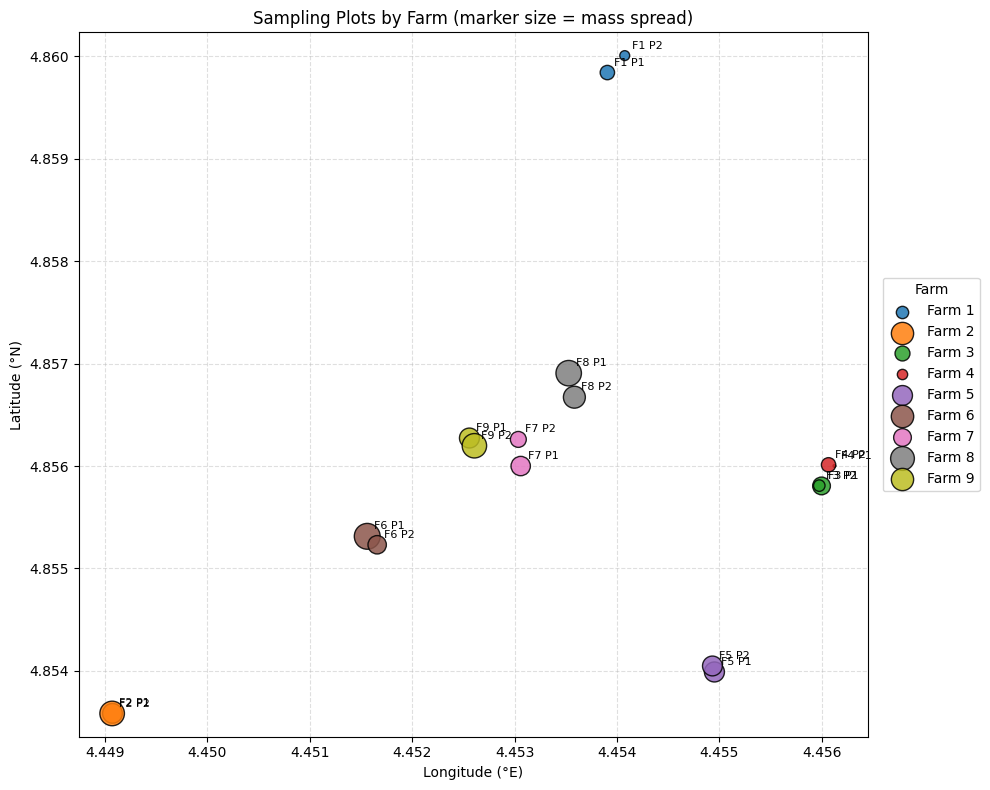

In [15]:
from pylab import *
import pandas as pd
from io import StringIO

csv_data = """Farm,Code,Latitude,Longitude,Mass_Range_g
Farm 1,F1 P1,4.859841,4.4539065,133.33 – 151.20
Farm 1,F1 P2,4.8600065,4.454076,145.72 – 154.14
Farm 2,F2 P1,4.853586,4.4490755,112.29 – 145.94
Farm 2,F2 P2,4.853585,4.4490725,107.15 – 159.31
Farm 3,F3 P1,4.855806,4.455997,124.42 – 151.56
Farm 3,F3 P2,4.855809,4.455975,138.96 – 150.36
Farm 4,F4 P1,4.856001,4.456123,150.20 – 150.86
Farm 4,F4 P2,4.856012,4.4560655,135.47 – 153.23
Farm 5,F5 P1,4.85399,4.4549515,119.16 – 153.75
Farm 5,F5 P2,4.8540485,4.454932,117.64 – 151.59
Farm 6,F6 P1,4.855314,4.4515625,102.00 – 159.73
Farm 6,F6 P2,4.8552315,4.4516595,117.14 – 146.37
Farm 7,F7 P1,4.856,4.4530605,117.55 – 149.88
Farm 7,F7 P2,4.85626,4.4530375,127.42 – 149.29
Farm 8,F8 P1,4.8569065,4.453529,95.45 – 151.53
Farm 8,F8 P2,4.856672,4.4535845,109.72 – 151.31
Farm 9,F9 P1,4.8562735,4.45256,121.25 – 155.50
Farm 9,F9 P2,4.856198,4.4526085,102.12 – 153.64
"""

data = pd.read_csv(StringIO(csv_data))

mass = data["Mass_Range_g"].str.split("–", expand=True)
data["Mass_Min_g"] = mass[0].str.strip().astype(float)
data["Mass_Max_g"] = mass[1].str.strip().astype(float)
data["Mass_Spread_g"] = data["Mass_Max_g"] - data["Mass_Min_g"]

# ---- Map with pylab ----
figure(figsize=(10, 8))

farms = sorted(data["Farm"].unique())
colors = cm.tab10(linspace(0, 1, 10))

for i, farm in enumerate(farms):
    g = data[data["Farm"] == farm]
    scatter(g["Longitude"], g["Latitude"],
            s=g["Mass_Spread_g"] * 6,          # marker size = mass spread
            color=colors[i % 10], edgecolor="black",
            alpha=0.85, label=farm, zorder=3)

# Label each point with its plot code
for _, r in data.iterrows():
    annotate(r["Code"], (r["Longitude"], r["Latitude"]),
             xytext=(5, 5), textcoords="offset points", fontsize=8)

# Padding so points aren't on the edge
pad = 0.0008
xlim(data["Longitude"].min() - pad, data["Longitude"].max() + pad)
ylim(data["Latitude"].min() - pad, data["Latitude"].max() + pad)

xlabel("Longitude (°E)")
ylabel("Latitude (°N)")
title("Sampling Plots by Farm (marker size = mass spread)")
legend(title="Farm", loc="center left", bbox_to_anchor=(1.01, 0.5))
grid(True, linestyle="--", alpha=0.4)
ticklabel_format(useOffset=False)   # show full coordinate values
gca().set_aspect("equal", adjustable="datalim")
tight_layout()
savefig("farm_map_pylab.png", dpi=300, bbox_inches="tight")
show()

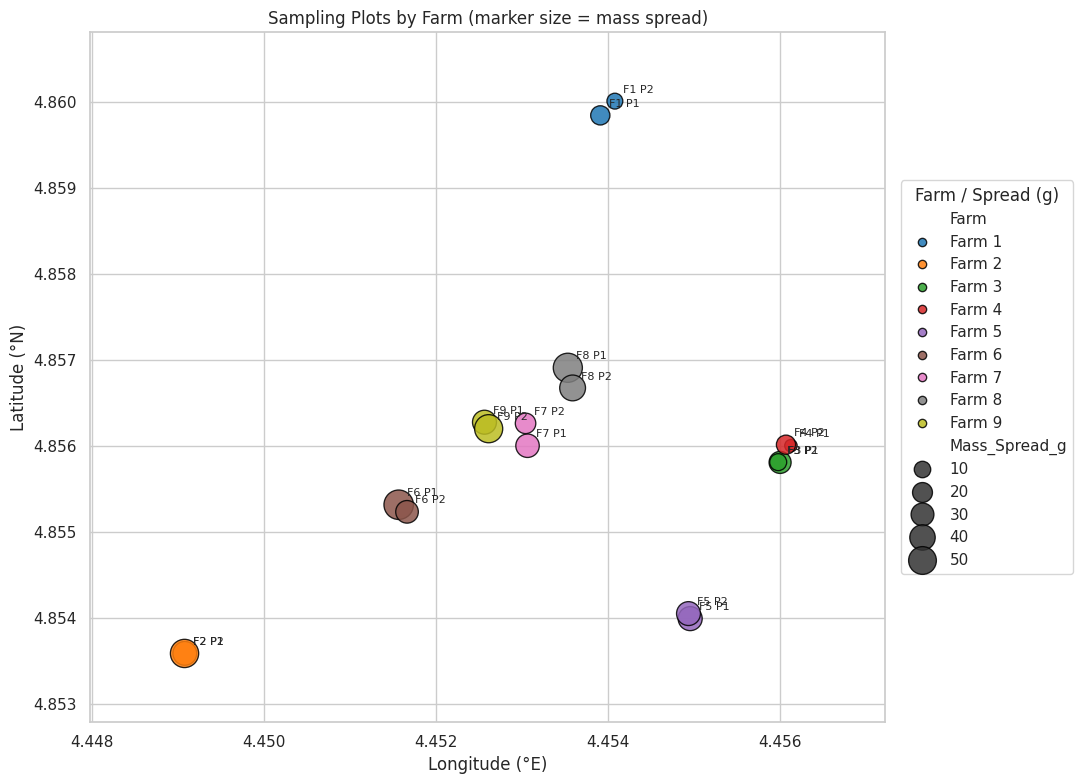

In [16]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from io import StringIO

csv_data = """Farm,Code,Latitude,Longitude,Mass_Range_g
Farm 1,F1 P1,4.859841,4.4539065,133.33 – 151.20
Farm 1,F1 P2,4.8600065,4.454076,145.72 – 154.14
Farm 2,F2 P1,4.853586,4.4490755,112.29 – 145.94
Farm 2,F2 P2,4.853585,4.4490725,107.15 – 159.31
Farm 3,F3 P1,4.855806,4.455997,124.42 – 151.56
Farm 3,F3 P2,4.855809,4.455975,138.96 – 150.36
Farm 4,F4 P1,4.856001,4.456123,150.20 – 150.86
Farm 4,F4 P2,4.856012,4.4560655,135.47 – 153.23
Farm 5,F5 P1,4.85399,4.4549515,119.16 – 153.75
Farm 5,F5 P2,4.8540485,4.454932,117.64 – 151.59
Farm 6,F6 P1,4.855314,4.4515625,102.00 – 159.73
Farm 6,F6 P2,4.8552315,4.4516595,117.14 – 146.37
Farm 7,F7 P1,4.856,4.4530605,117.55 – 149.88
Farm 7,F7 P2,4.85626,4.4530375,127.42 – 149.29
Farm 8,F8 P1,4.8569065,4.453529,95.45 – 151.53
Farm 8,F8 P2,4.856672,4.4535845,109.72 – 151.31
Farm 9,F9 P1,4.8562735,4.45256,121.25 – 155.50
Farm 9,F9 P2,4.856198,4.4526085,102.12 – 153.64
"""

data = pd.read_csv(StringIO(csv_data))

mass = data["Mass_Range_g"].str.split("–", expand=True)
data["Mass_Min_g"] = mass[0].str.strip().astype(float)
data["Mass_Max_g"] = mass[1].str.strip().astype(float)
data["Mass_Spread_g"] = data["Mass_Max_g"] - data["Mass_Min_g"]
data["Mass_Mid_g"] = (data["Mass_Min_g"] + data["Mass_Max_g"]) / 2

# ---- Map with seaborn ----
sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(11, 8))

sns.scatterplot(
    data=data,
    x="Longitude", y="Latitude",
    hue="Farm", palette="tab10",
    size="Mass_Spread_g", sizes=(80, 450),   # marker size = mass spread
    edgecolor="black", alpha=0.85,
    ax=ax,
)

# Label each point with its plot code
for _, r in data.iterrows():
    ax.annotate(r["Code"], (r["Longitude"], r["Latitude"]),
                xytext=(6, 6), textcoords="offset points", fontsize=8)

pad = 0.0008
ax.set_xlim(data["Longitude"].min() - pad, data["Longitude"].max() + pad)
ax.set_ylim(data["Latitude"].min() - pad, data["Latitude"].max() + pad)
ax.ticklabel_format(useOffset=False)          # show full coordinate values
ax.set_aspect("equal", adjustable="datalim")

ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.set_title("Sampling Plots by Farm (marker size = mass spread)")
ax.legend(title="Farm / Spread (g)", loc="center left",
          bbox_to_anchor=(1.01, 0.5), frameon=True)

plt.tight_layout()
plt.savefig("farm_map_seaborn.png", dpi=300, bbox_inches="tight")
plt.show()

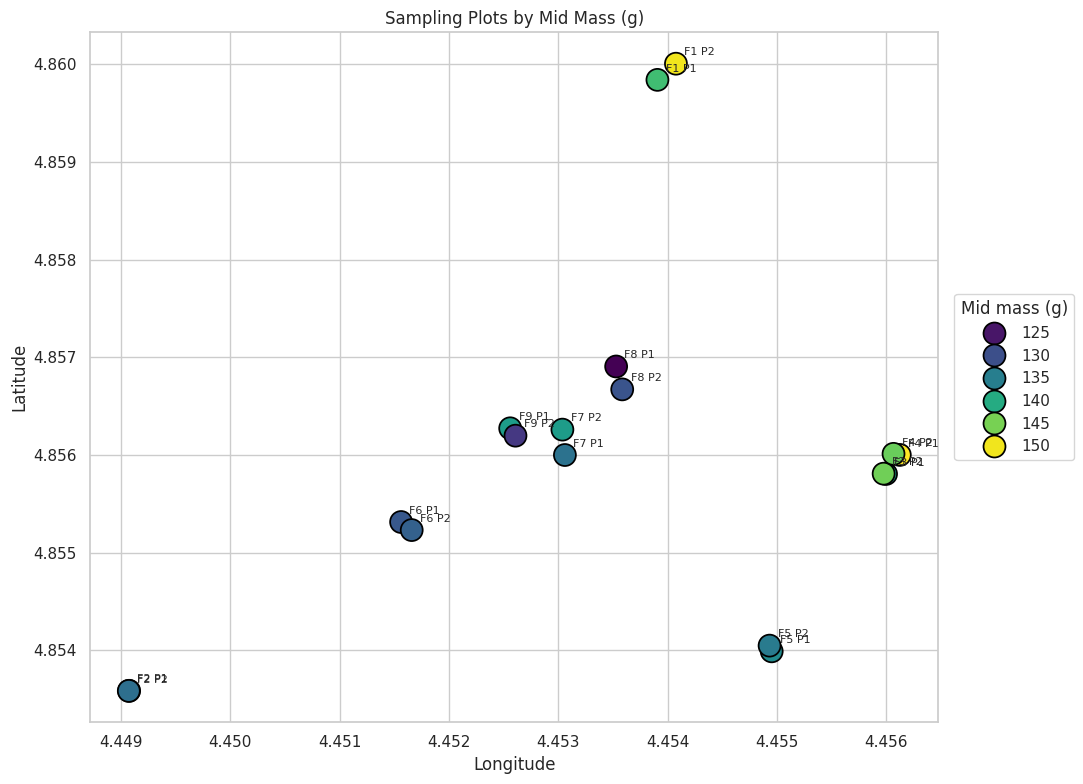

In [17]:
fig, ax = plt.subplots(figsize=(11, 8))

sns.scatterplot(
    data=data, x="Longitude", y="Latitude",
    hue="Mass_Mid_g", palette="viridis",
    s=250, edgecolor="black", ax=ax,
)

for _, r in data.iterrows():
    ax.annotate(r["Code"], (r["Longitude"], r["Latitude"]),
                xytext=(6, 6), textcoords="offset points", fontsize=8)

ax.ticklabel_format(useOffset=False)
ax.set_title("Sampling Plots by Mid Mass (g)")
ax.legend(title="Mid mass (g)", loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.show()